# Chapter 2: first simulations for MAE 552: start here

**Cover and Thomas, *Elements of Information Theory*, 2nd edition, Chapter 2:
entropy, relative entropy, and mutual information.**

These notebooks are a small laboratory for the definitions and theorems of
Chapter 2. 

Each notebook takes one section of the chapter, states the
definition or theorem in one or two lines, and then computes it, plots it, or
tests it on simulated data.

The code is deliberately plain. It uses only `numpy` for arrays and
`matplotlib` for plots. There are no classes, no decorators and no clever
tricks. If you can read a `for` loop and an array index, you can read every
cell here.

## The notebooks

| Notebook | Section of the book | What you will see |
|---|---|---|
| `01_entropy.ipynb` | 2.1 | $H(X)$, the binary entropy curve, the 20-questions interpretation, entropy estimated from samples |
| `02_joint_and_conditional_entropy.ipynb` | 2.2 | $H(X,Y)$, $H(X\mid Y)$, the chain rule, the book's 4 by 4 example |
| `03_relative_entropy_and_mutual_information.ipynb` | 2.3, 2.4 | $D(p\Vert q)$, its asymmetry, $I(X;Y)$, the Venn diagram, the binary symmetric channel |
| `04_chain_rules.ipynb` | 2.5 | chain rules for $H$, $I$ and $D$; conditional mutual information |
| `05_jensen_and_inequalities.ipynb` | 2.6, 2.7 | Jensen, $D \ge 0$, $H \le \log\lvert\mathcal X\rvert$, conditioning reduces entropy, concavity of $H$ |
| `06_data_processing.ipynb` | 2.8 | $X \to Y \to Z$ implies $I(X;Y) \ge I(X;Z)$, cascades of noisy channels |
| `07_sufficient_statistics.ipynb` | 2.9 | $I(\theta;X) = I(\theta;T(X))$ exactly when $T$ is sufficient |
| `08_fano.ipynb` | 2.10 | Fano's inequality, the error probability of the best guess |

Run them in order the first time. After that each notebook is self-contained
and can be opened on its own.

## Conventions used in every notebook

* A **distribution** is a numpy array of non-negative numbers that sum to 1.
* A **joint distribution** of $(X,Y)$ is a 2-D array `P` with
  `P[i, j]` $= p(X = i, Y = j)$. Rows are values of $X$, columns are values of $Y$.
* All logarithms are base 2, so every quantity is in **bits**.
* The convention $0 \log 0 = 0$ is built into the helper functions.

The helper functions live in `infotools.py`, in the same folder. They are
short on purpose: open that file and read them alongside the definitions in
the book.

## Step 1: check that the environment works

Run the cell below. It should print the versions of the three packages that
these notebooks need. If it raises an error, go back to `README.md` and run
the setup script again.

In [1]:
import sys
import numpy as np
import scipy
import matplotlib

print("Python     ", sys.version.split()[0])
print("numpy      ", np.__version__)
print("scipy      ", scipy.__version__)
print("matplotlib ", matplotlib.__version__)

try:
    import ipywidgets
    print("ipywidgets ", ipywidgets.__version__, "(sliders available)")
except ImportError:
    print("ipywidgets  not installed (the notebooks still run, without sliders)")

Python      3.13.5
numpy       2.5.3
scipy       1.18.1
matplotlib  3.11.1
ipywidgets  8.1.9 (sliders available)


## Step 2: check that the helper functions work

The next cell reproduces the numbers of Example 2.2.1 of the book, whose
joint distribution is

$$
p(x,y) =
\begin{array}{c|cccc}
 & x=1 & x=2 & x=3 & x=4 \\ \hline
y=1 & 1/8 & 1/16 & 1/32 & 1/32 \\
y=2 & 1/16 & 1/8 & 1/32 & 1/32 \\
y=3 & 1/16 & 1/16 & 1/16 & 1/16 \\
y=4 & 1/4 & 0 & 0 & 0
\end{array}
$$

The book reports $H(X) = 7/4$, $H(Y) = 2$, $H(X\mid Y) = 11/8$,
$H(Y\mid X) = 13/8$, $H(X,Y) = 27/8$ and $I(X;Y) = 0.375$, all in bits.

In [2]:
import infotools as it

# The book writes the table with x across the top. We store it with x as the
# row index, so we write the book's table and then transpose it.
book_table = np.array([
    [1/8,  1/16, 1/32, 1/32],   # y = 1
    [1/16, 1/8,  1/32, 1/32],   # y = 2
    [1/16, 1/16, 1/16, 1/16],   # y = 3
    [1/4,  0,    0,    0   ],   # y = 4
])
P = book_table.T                # now P[i, j] = p(X = i+1, Y = j+1)

print("H(X)   =", it.entropy(it.marginal_X(P)),        " book: 7/4  =", 7/4)
print("H(Y)   =", it.entropy(it.marginal_Y(P)),        " book: 2")
print("H(X|Y) =", it.cond_entropy_X_given_Y(P),        " book: 11/8 =", 11/8)
print("H(Y|X) =", it.cond_entropy_Y_given_X(P),        " book: 13/8 =", 13/8)
print("H(X,Y) =", it.joint_entropy(P),                 " book: 27/8 =", 27/8)
print("I(X;Y) =", it.mutual_information(P),            " book: 0.375")

H(X)   = 1.75  book: 7/4  = 1.75
H(Y)   = 2.0  book: 2
H(X|Y) = 1.375  book: 11/8 = 1.375
H(Y|X) = 1.625  book: 13/8 = 1.625
H(X,Y) = 3.375  book: 27/8 = 3.375
I(X;Y) = 0.375  book: 0.375


If those six numbers match the book, everything is installed correctly.

## Step 3: check that plots appear

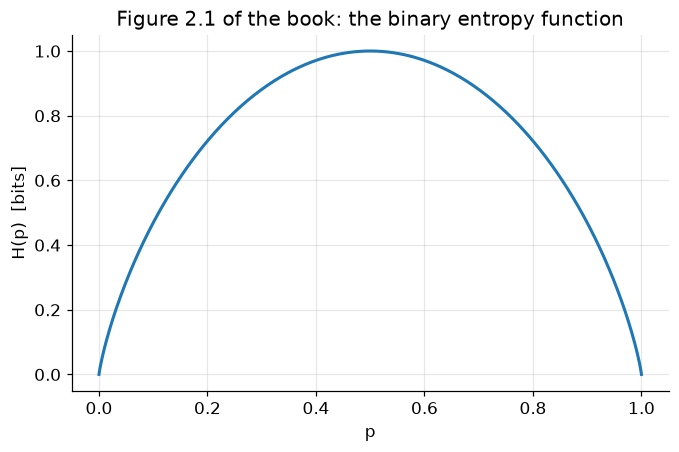

In [3]:
import matplotlib.pyplot as plt

it.setup_plot_style()

p = np.linspace(0, 1, 501)
plt.plot(p, it.binary_entropy(p), color=it.COLORS["H"])
plt.xlabel("p")
plt.ylabel("H(p)  [bits]")
plt.title("Figure 2.1 of the book: the binary entropy function")
plt.show()

You should see a curve that is 0 at $p = 0$ and $p = 1$ and reaches 1 bit at
$p = 1/2$.

## How to use these notebooks in class

Every notebook follows the same sequence:

1. a short markdown cell stating the definition or theorem, in the notation
   of the book;
2. one code cell that computes it on a small, concrete example whose answer
   you can also check by hand;
3. one code cell that runs a simulation or draws a picture;
4. a few `[PASS]` lines that test the theorem on many random distributions,
   so you can see that it is not an accident of the example chosen.

The numbers you are meant to change are always at the top of a cell and have
a comment saying so. Change one, re-run the cell, and watch what moves.

## A note on the `[PASS]` lines

Several cells print lines like

```
[PASS] D(p||q) >= 0 on 2000 random pairs
```

These are numerical tests of the theorems. They do not replace the proofs in
the book. They are there so that you can see immediately that an inequality
is not being violated, and so that if you modify a cell and break something,
you find out at once.